# Task 2 — California Housing Price Prediction
### Data cleaning, exploratory data analysis, feature engineering, model training and evaluation

**Objective:** Predict `median_house_value` from California housing census features.

**Workflow**
1. Load and inspect the data.
2. Clean missing values and check duplicates.
3. Explore distributions, relationships and geographic patterns.
4. Build leakage-safe preprocessing and engineered features.
5. Compare regression models with consistent evaluation metrics.
6. Tune the strongest candidate using cross-validation.
7. Visualize predictions, residuals and feature importance.

In [1]:
# 1. Import libraries and configure display

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

RANDOM_STATE = 42

## 2. Load the dataset

In [2]:
# Load the CSV file from the notebook's working directory.
data = pd.read_csv("housing.csv")

print(f"Dataset shape: {data.shape[0]:,} rows × {data.shape[1]} columns")
display(data.head())

Dataset shape: 20,640 rows × 10 columns


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


## 3. Initial data inspection

In [3]:
# Review column types, summary statistics, missing values and exact duplicate rows.
data.info()
display(data.describe(include="all").T)

missing_summary = (
    data.isna().sum()
    .rename("missing_count")
    .to_frame()
)
display(missing_summary)

print("Exact duplicate rows:", data.duplicated().sum())
print("\nColumn names:", data.columns.tolist())

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.7 MB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
longitude,20640.0,NaN,NaN,NaN,-119.569704,2.003532,-124.35,-121.8,-118.49,-118.01,-114.31
latitude,20640.0,NaN,NaN,NaN,35.631861,2.135952,32.54,33.93,34.26,37.71,41.95
housing_median_age,20640.0,NaN,NaN,NaN,28.639486,12.585558,1.0,18.0,29.0,37.0,52.0
total_rooms,20640.0,NaN,NaN,NaN,2635.763081,2181.615252,2.0,1447.75,2127.0,3148.0,39320.0
total_bedrooms,20433.0,NaN,NaN,NaN,537.870553,421.38507,1.0,296.0,435.0,647.0,6445.0
population,20640.0,NaN,NaN,NaN,1425.476744,1132.462122,3.0,787.0,1166.0,1725.0,35682.0
households,20640.0,NaN,NaN,NaN,499.53968,382.329753,1.0,280.0,409.0,605.0,6082.0
median_income,20640.0,NaN,NaN,NaN,3.870671,1.899822,0.4999,2.5634,3.5348,4.74325,15.0001
median_house_value,20640.0,NaN,NaN,NaN,206855.816909,115395.615874,14999.0,119600.0,179700.0,264725.0,500001.0
ocean_proximity,20640,5,<1H OCEAN,9136,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,missing_count
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,207
population,0
households,0
median_income,0
median_house_value,0
ocean_proximity,0


Exact duplicate rows: 0

Column names: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value', 'ocean_proximity']


## 4. Data quality and cleaning

In [ ]:
# Make a separate working copy. Keep the raw data unchanged for reference.

df = data.copy()

target = "median_house_value"
if target not in df.columns:
    raise ValueError(f"Expected target column '{target}' was not found.")

# Remove rows where the target is missing; a supervised model cannot learn from them.

before = len(df)
df = df.dropna(subset=[target]).copy()
print(f"Rows removed due to missing target: {before - len(df)}")

# Ensure the target is numeric.

df[target] = pd.to_numeric(df[target], errors="coerce")
df = df.dropna(subset=[target]).copy()

print("Shape after target validation:", df.shape)
print("Remaining missing values (predictors):", int(df.drop(columns=target).isna().sum().sum()))

Rows removed due to missing target: 0
Shape after target validation: (20640, 10)
Remaining missing values (predictors): 207


## 5. Exploratory data analysis (EDA)

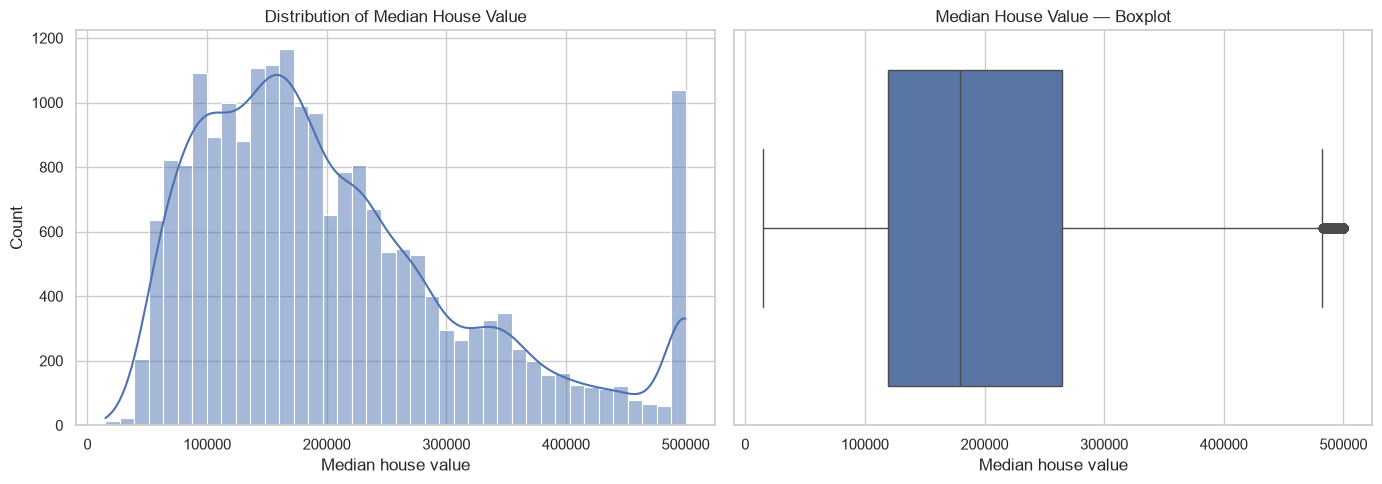

,median_house_value
count,20640.000000
mean,206855.816909
std,115395.615874
min,14999.000000
25%,119600.000000
50%,179700.000000
75%,264725.000000
max,500001.000000


In [ ]:
# Target distribution: skew, range and potential ceiling effect.

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df[target], bins=40, kde=True, ax=axes[0])
axes[0].set_title("Distribution of Median House Value")
axes[0].set_xlabel("Median house value")
sns.boxplot(x=df[target], ax=axes[1])
axes[1].set_title("Median House Value — Boxplot")
axes[1].set_xlabel("Median house value")
plt.tight_layout()
plt.show()

display(df[target].describe().to_frame("median_house_value"))

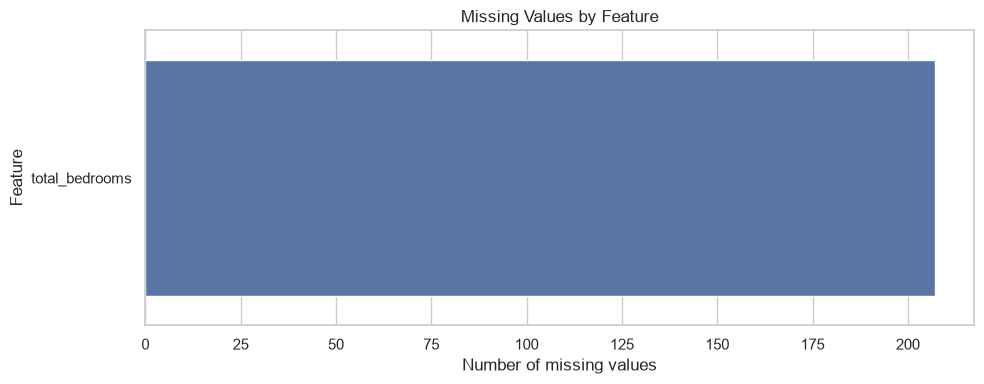

In [ ]:
# Missingness chart

missing_counts = df.isna().sum().sort_values(ascending=False)
missing_counts = missing_counts[missing_counts > 0]
if len(missing_counts):
    plt.figure(figsize=(10, 4))
    sns.barplot(x=missing_counts.values, y=missing_counts.index)
    plt.title("Missing Values by Feature")
    plt.xlabel("Number of missing values")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values detected.")

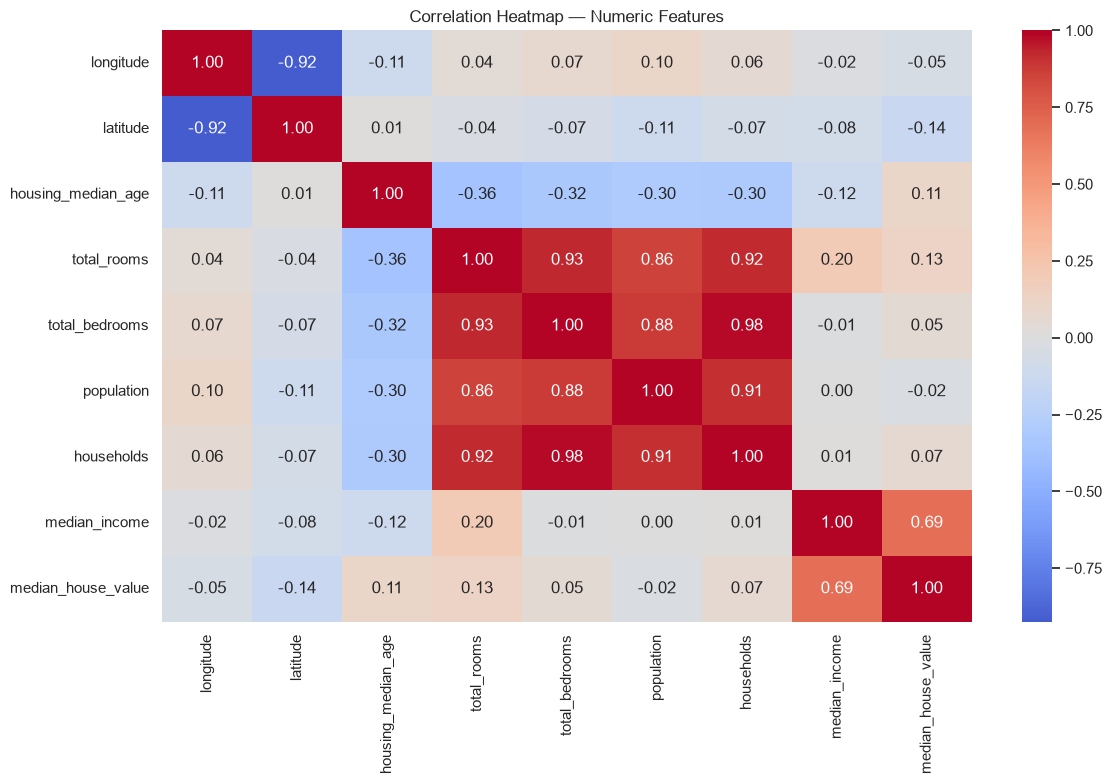

In [ ]:
# Correlation heatmap for numeric columns. Correlation is association, not causation.

numeric_df = df.select_dtypes(include=np.number)
plt.figure(figsize=(12, 8))
sns.heatmap(numeric_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap — Numeric Features")
plt.tight_layout()
plt.show()

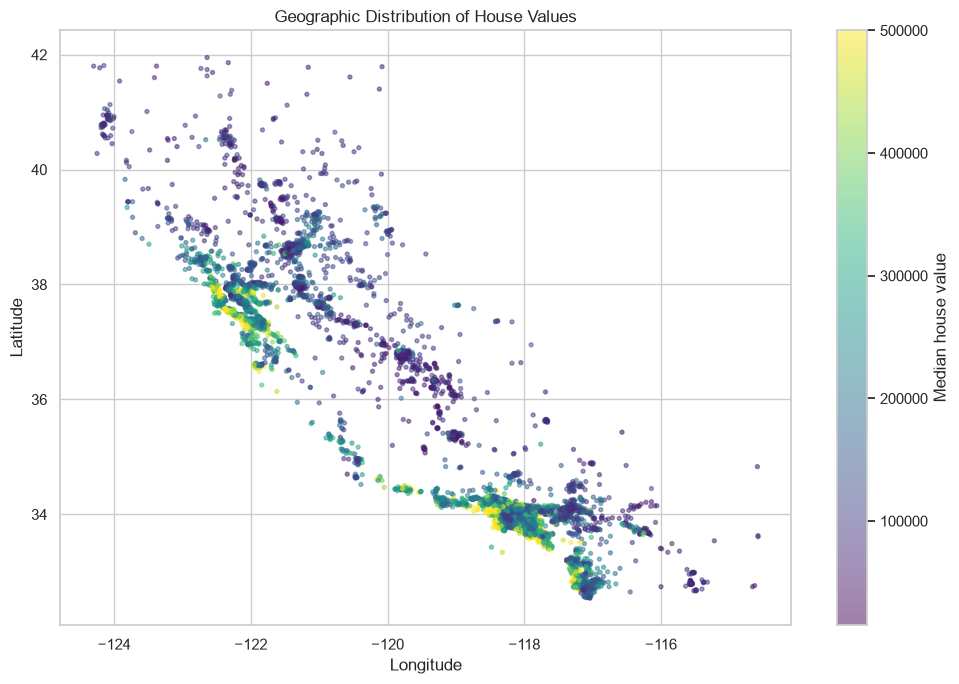

In [8]:
# Geographic view of California housing records (if coordinates are available).

if {"longitude", "latitude"}.issubset(df.columns):
    plot_data = df.sample(min(8000, len(df)), random_state=RANDOM_STATE)
    plt.figure(figsize=(10, 7))
    points = plt.scatter(
        plot_data["longitude"], plot_data["latitude"],
        c=plot_data[target], s=8, alpha=0.5, cmap="viridis"
    )
    plt.colorbar(points, label="Median house value")
    plt.title("Geographic Distribution of House Values")
    plt.xlabel("Longitude")
    plt.ylabel("Latitude")
    plt.tight_layout()
    plt.show()
else:
    print("Latitude/longitude columns not found; geographic plot skipped.")

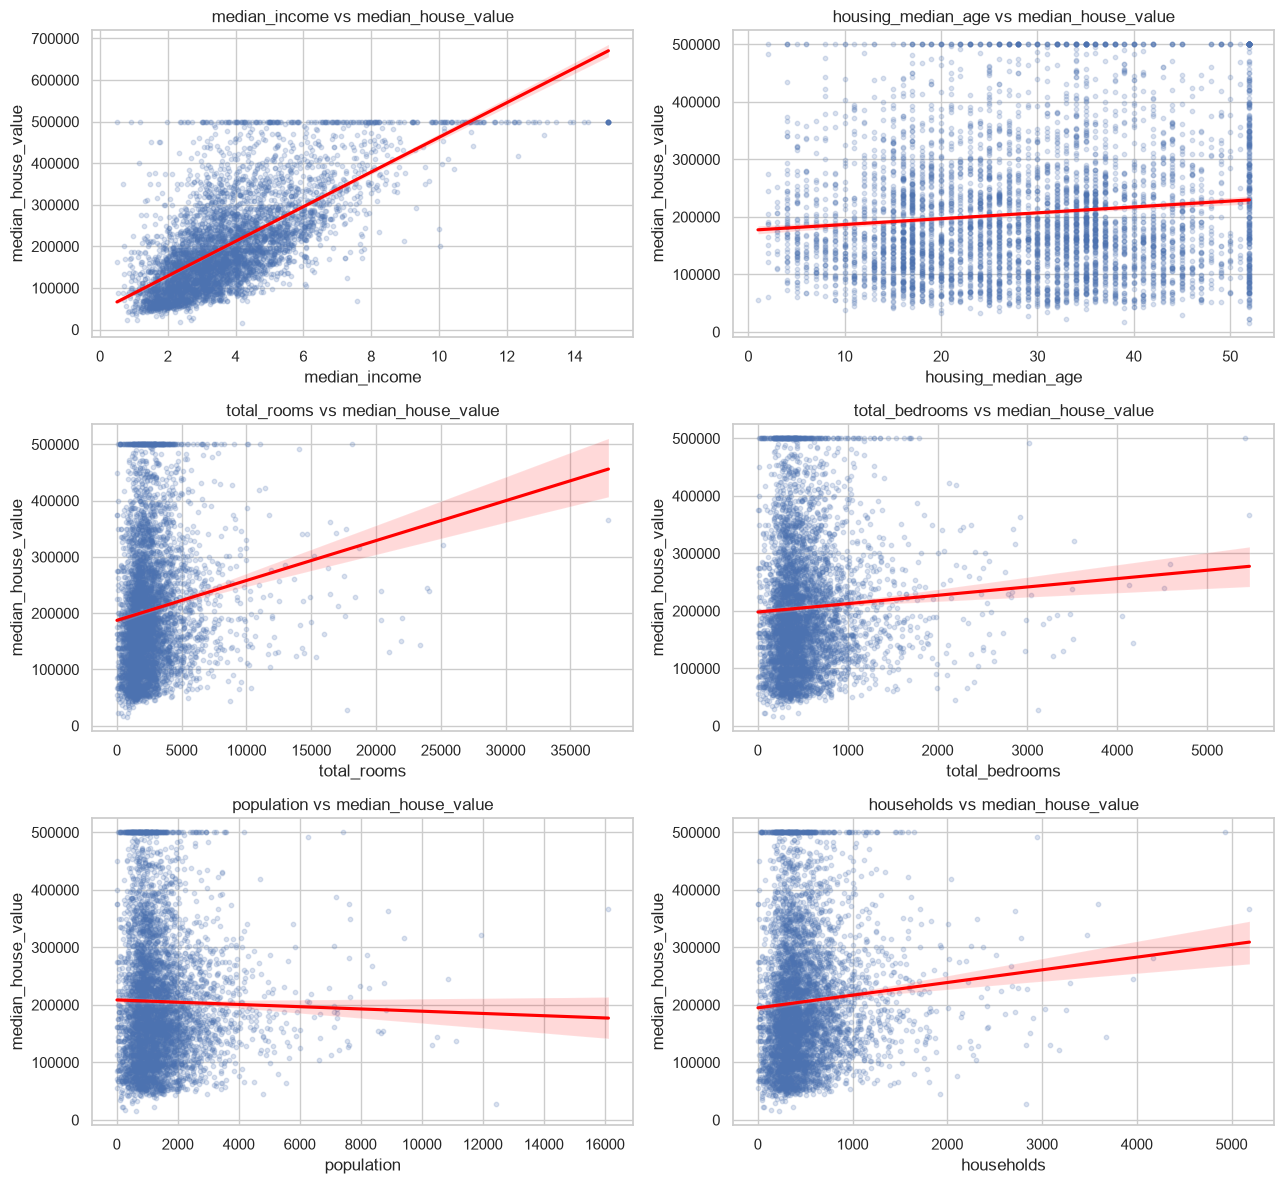

In [ ]:
# Inspect selected relationships with the target.

candidate_features = [c for c in ["median_income", "housing_median_age", "total_rooms",
                                  "total_bedrooms", "population", "households"] if c in df.columns]
if candidate_features:
    ncols = 2
    nrows = int(np.ceil(len(candidate_features) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(13, 4 * nrows))
    axes = np.array(axes).reshape(-1)
    for ax, feature in zip(axes, candidate_features):
        sns.regplot(data=df.sample(min(5000, len(df)), random_state=RANDOM_STATE),
                    x=feature, y=target, scatter_kws={"alpha": 0.2, "s": 10},
                    line_kws={"color": "red"}, ax=ax)
        ax.set_title(f"{feature} vs {target}")
    for ax in axes[len(candidate_features):]:
        ax.remove()
    plt.tight_layout()
    plt.show()

## 6. Feature engineering

In [ ]:
X = df.drop(columns=[target])
y = df[target].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])
print("Predictor columns:", X_train.shape[1])

Training rows: 16512
Testing rows: 4128
Predictor columns: 9


## 7. Preprocessing pipeline

In [ ]:
# Identify numeric and categorical predictors from the training data.

numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Preprocessing is fit only on the training data through each model pipeline.")

Numeric features: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income']
Categorical features: ['ocean_proximity']
Preprocessing is fit only on the training data through each model pipeline.


## 8. Train and compare models

In [ ]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=10.0),
    "Lasso": Lasso(alpha=0.001, max_iter=20000),
    "Random Forest": RandomForestRegressor(
        n_estimators=160, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1
    )
}

fitted_models = {}
predictions = {}
results = []

for name, estimator in models.items():
    pipe = Pipeline(steps=[("preprocessor", preprocessor), ("model", estimator)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    fitted_models[name] = pipe
    predictions[name] = pred
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": mean_squared_error(y_test, pred) ** 0.5,
        "R2": r2_score(y_test, pred)
    })

results_df = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)
display(results_df.style.format({"MAE": "{:,.0f}", "RMSE": "{:,.0f}", "R2": "{:.4f}"}))

C:\Users\HP\AppData\Roaming\Python\Python313\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 6.262730e+12, tolerance: 2.207e+10
  model = cd_fast.enet_coordinate_descent(


,Model,MAE,RMSE,R2
0,Random Forest,"31,473","48,839",0.8180
1,Linear Regression,"50,670","70,059",0.6254
2,Lasso,"50,670","70,059",0.6254
3,Ridge,"50,683","70,082",0.6252


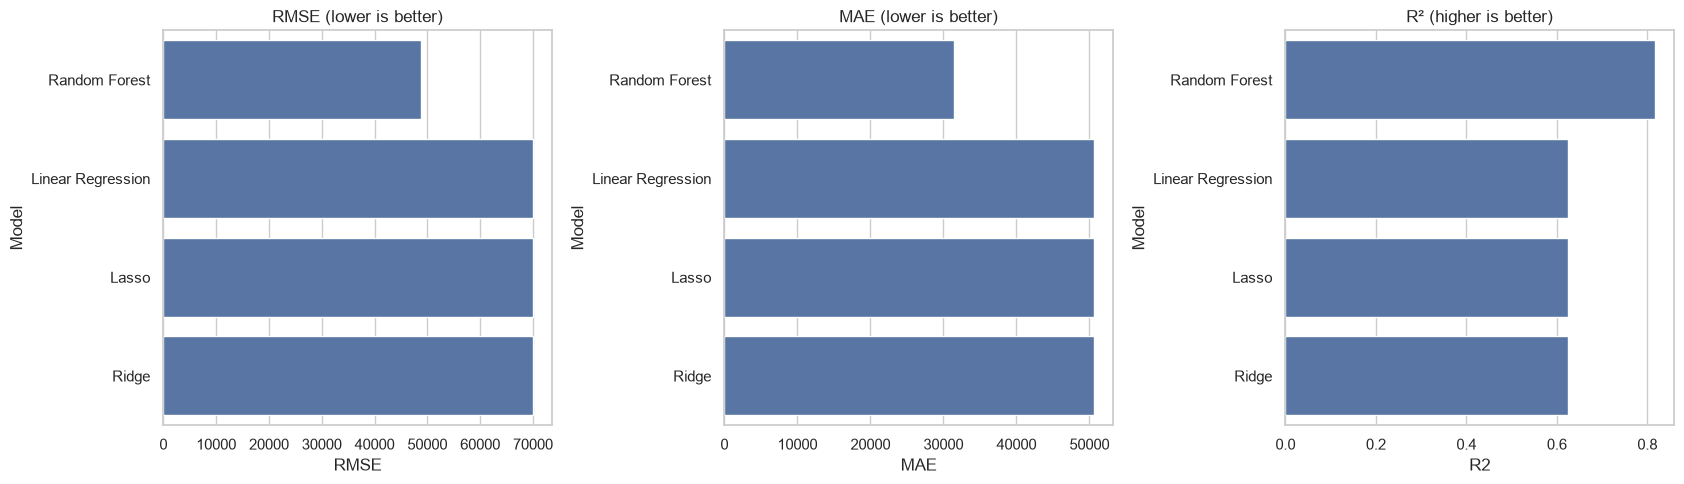

In [ ]:
# Visual comparison of test metrics.

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
sns.barplot(data=results_df, x="RMSE", y="Model", ax=axes[0])
axes[0].set_title("RMSE (lower is better)")
sns.barplot(data=results_df, x="MAE", y="Model", ax=axes[1])
axes[1].set_title("MAE (lower is better)")
sns.barplot(data=results_df, x="R2", y="Model", ax=axes[2])
axes[2].set_title("R² (higher is better)")
plt.tight_layout()
plt.show()

## 9. Hyperparameter tuning

In [ ]:
rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1))
])

param_grid = {
    "model__n_estimators": [120, 200],
    "model__max_depth": [None, 20],
    "model__min_samples_leaf": [1, 2]
}

rf_search = GridSearchCV(
    rf_pipeline,
    param_grid=param_grid,
    scoring="neg_root_mean_squared_error",
    cv=3,
    n_jobs=-1,
    verbose=1
)
rf_search.fit(X_train, y_train)

print("Best parameters:", rf_search.best_params_)
print(f"Best cross-validation RMSE: {-rf_search.best_score_:,.2f}")

tuned_rf = rf_search.best_estimator_
tuned_rf_pred = tuned_rf.predict(X_test)

tuned_metrics = {
    "Model": "Tuned Random Forest",
    "MAE": mean_absolute_error(y_test, tuned_rf_pred),
    "RMSE": mean_squared_error(y_test, tuned_rf_pred) ** 0.5,
    "R2": r2_score(y_test, tuned_rf_pred)
}
display(pd.DataFrame([tuned_metrics]).style.format({"MAE": "{:,.0f}", "RMSE": "{:,.0f}", "R2": "{:.4f}"}))

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best parameters: {'model__max_depth': None, 'model__min_samples_leaf': 2, 'model__n_estimators': 200}
Best cross-validation RMSE: 49,953.67


,Model,MAE,RMSE,R2
0,Tuned Random Forest,"31,450","48,793",0.8183


## 10. Final model selection

In [ ]:
# Compare the tuned model against the initial candidates on the same held-out test set.

final_comparison = pd.concat(
    [results_df, pd.DataFrame([tuned_metrics])],
    ignore_index=True
).sort_values("RMSE").reset_index(drop=True)

display(final_comparison.style.format({"MAE": "{:,.0f}", "RMSE": "{:,.0f}", "R2": "{:.4f}"}))

best_name = final_comparison.iloc[0]["Model"]
if best_name == "Tuned Random Forest":
    best_model = tuned_rf
    best_predictions = tuned_rf_pred
else:
    best_model = fitted_models[best_name]
    best_predictions = predictions[best_name]

print("Best model by held-out RMSE:", best_name)
print(f"MAE:  {mean_absolute_error(y_test, best_predictions):,.2f}")
print(f"RMSE: {mean_squared_error(y_test, best_predictions) ** 0.5:,.2f}")
print(f"R²:   {r2_score(y_test, best_predictions):.4f}")

,Model,MAE,RMSE,R2
0,Tuned Random Forest,"31,450","48,793",0.8183
1,Random Forest,"31,473","48,839",0.8180
2,Linear Regression,"50,670","70,059",0.6254
3,Lasso,"50,670","70,059",0.6254
4,Ridge,"50,683","70,082",0.6252


Best model by held-out RMSE: Tuned Random Forest
MAE:  31,450.15
RMSE: 48,793.05
R²:   0.8183


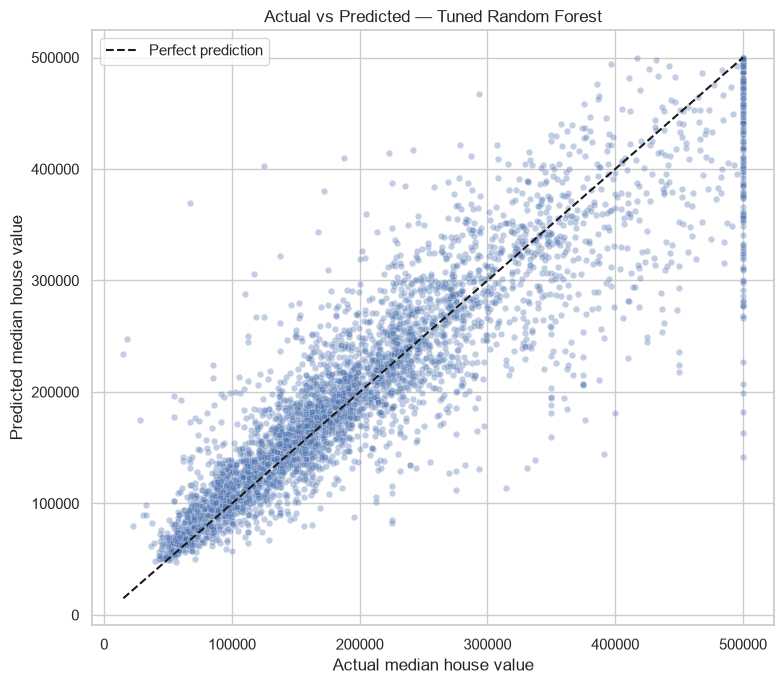

In [ ]:
# Actual vs predicted: points near the diagonal are more accurate.

plt.figure(figsize=(8, 7))
sns.scatterplot(x=y_test, y=best_predictions, alpha=0.35, s=22)
low = min(float(y_test.min()), float(np.min(best_predictions)))
high = max(float(y_test.max()), float(np.max(best_predictions)))
plt.plot([low, high], [low, high], "k--", label="Perfect prediction")
plt.title(f"Actual vs Predicted — {best_name}")
plt.xlabel("Actual median house value")
plt.ylabel("Predicted median house value")
plt.legend()
plt.tight_layout()
plt.show()

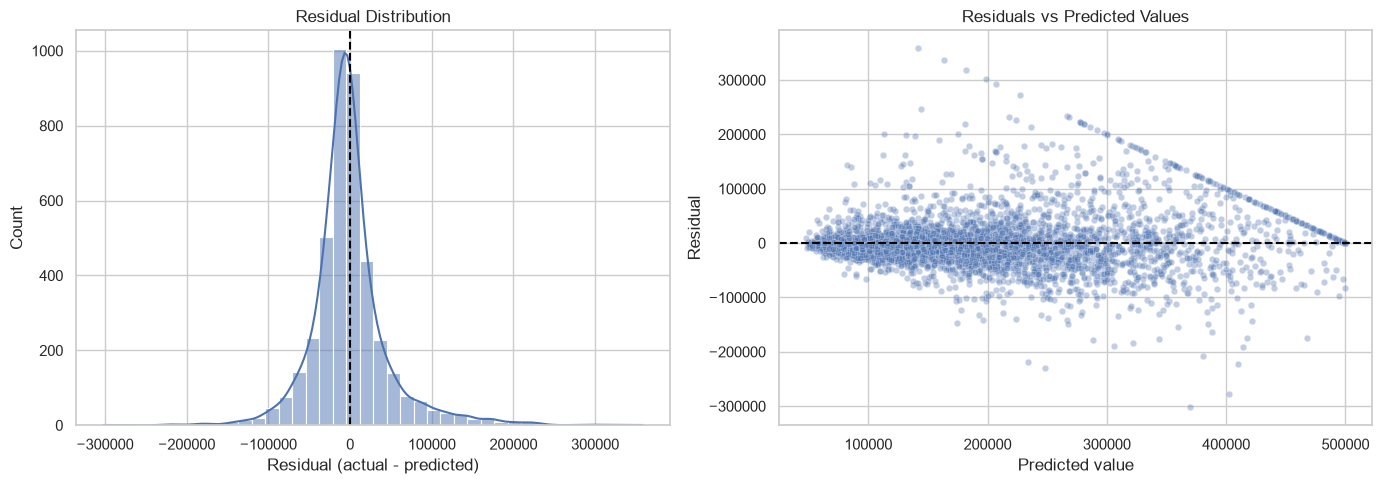

In [ ]:
# Residual analysis: residual = actual - predicted.

residuals = y_test.to_numpy() - best_predictions

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(residuals, bins=40, kde=True, ax=axes[0])
axes[0].axvline(0, linestyle="--", color="black")
axes[0].set_title("Residual Distribution")
axes[0].set_xlabel("Residual (actual - predicted)")

sns.scatterplot(x=best_predictions, y=residuals, alpha=0.35, s=22, ax=axes[1])
axes[1].axhline(0, linestyle="--", color="black")
axes[1].set_title("Residuals vs Predicted Values")
axes[1].set_xlabel("Predicted value")
axes[1].set_ylabel("Residual")
plt.tight_layout()
plt.show()

In [ ]:
# Error distribution by actual-value quantile can reveal where the model struggles.

error_analysis = pd.DataFrame({
    "actual": y_test.to_numpy(),
    "predicted": best_predictions,
    "absolute_error": np.abs(y_test.to_numpy() - best_predictions),
    "residual": residuals
})
error_analysis["actual_value_group"] = pd.qcut(
    error_analysis["actual"], q=5, duplicates="drop"
)
display(error_analysis.groupby("actual_value_group", observed=False)
        .agg(records=("absolute_error", "size"),
             mean_absolute_error=("absolute_error", "mean"),
             median_absolute_error=("absolute_error", "median"))
        .round(2))

,records,mean_absolute_error,median_absolute_error
actual_value_group,,,
"(14998.999, 106940.0]",826,19161.54,12518.14
"(106940.0, 157700.0]",827,23117.01,15638.59
"(157700.0, 207140.0]",824,24811.12,17384.77
"(207140.0, 287420.0]",825,32830.46,24882.47
"(287420.0, 500001.0]",826,57326.32,41603.15


## 11. Feature importance

,Feature,Importance (R² decrease),Std
7,median_income,0.6569,0.0176
0,longitude,0.4709,0.0069
1,latitude,0.3846,0.0068
8,ocean_proximity,0.2142,0.0083
2,housing_median_age,0.0537,0.0026
5,population,0.0343,0.0022
3,total_rooms,0.0145,0.0007
4,total_bedrooms,0.0136,0.0014
6,households,0.0050,0.0007


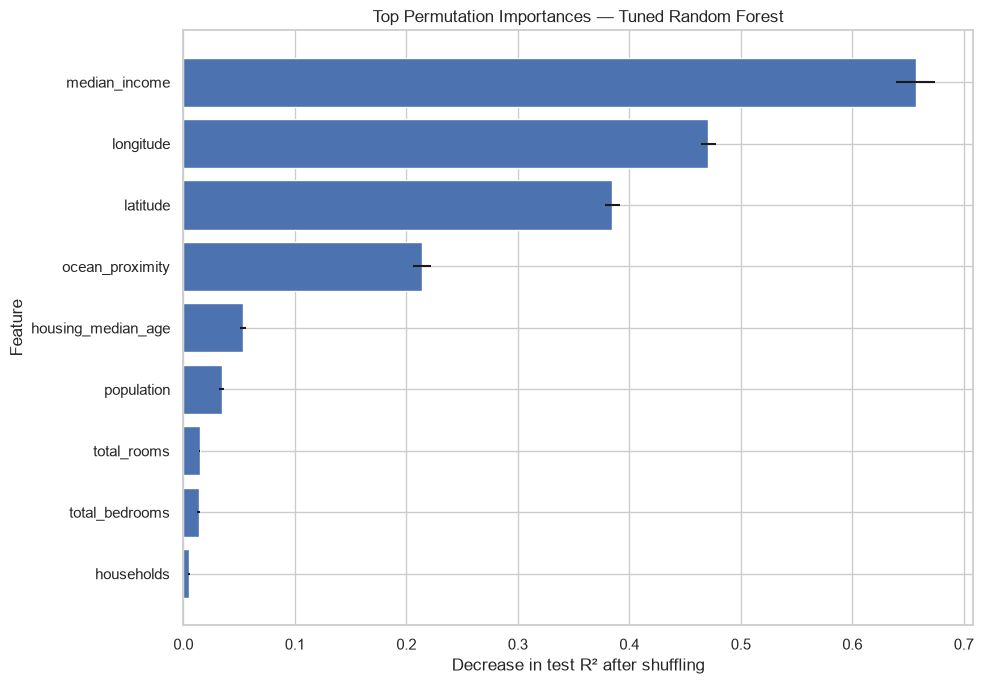

In [ ]:
# Permutation importance works with the complete preprocessing/model pipeline.
# It measures the drop in R² when a feature's values are shuffled.

perm = permutation_importance(
    best_model, X_test, y_test,
    n_repeats=5, random_state=RANDOM_STATE,
    scoring="r2", n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance (R² decrease)": perm.importances_mean,
    "Std": perm.importances_std
}).sort_values("Importance (R² decrease)", ascending=False)

display(importance_df.head(15).round(4))

top_importance = importance_df.head(15).sort_values("Importance (R² decrease)")
plt.figure(figsize=(10, 7))
plt.barh(top_importance["Feature"], top_importance["Importance (R² decrease)"],
         xerr=top_importance["Std"])
plt.title(f"Top Permutation Importances — {best_name}")
plt.xlabel("Decrease in test R² after shuffling")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()